# Lesson 1, one call at a time

Lesson 1 built a complete workflow on 569 tumours. This notebook takes four of the
steps it went through quickly, on eight to ten rows, so that every number can be
read: how a split is drawn and what `stratify` keeps, what a baseline learns, and
how the confusion matrix, precision and recall are counted.

**How to use it.** Each section is one *atom*. Before each code cell that teaches
something there is a question under *Your prediction, before you run the next cell*:
answer it first, then run. The notebook `00_the_scikit_learn_api.ipynb` covers what
`fit`, `predict`, `predict_proba` and `score` do in general, the threshold of 0.5
behind `predict`, and why the inputs are NumPy arrays of shape `(m, n)`; this one
assumes it.

Not examinable. The full-scale version of each atom is in lesson 1's notebook
`02_first_ml_workflow.ipynb`.


## Setup

In [1]:
# Everything used here ships with the course image:
# pip install numpy==1.26.4 scikit-learn==1.3.1 matplotlib==3.8.0

import matplotlib.pyplot as plt
import numpy as np
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (ConfusionMatrixDisplay, accuracy_score, classification_report,
                             confusion_matrix)
from sklearn.model_selection import train_test_split

np.set_printoptions(precision=3, suppress=True)


## 1. `train_test_split`, and what `stratify` keeps

`train_test_split(X, y)` shuffles the rows and returns four pieces, always in the
same order: training inputs, test inputs, training labels, test labels. With
`stratify=y` it draws the test rows so that each class keeps the share it has in the
whole dataset.

*From:* lesson 1, slide *Step 3: split, before anything else* and notebook 2, section *Split before you do anything else*.

In [2]:
# Eight patients, one measurement each; two of the eight are ill (label 1).
X = np.array([[1.0], [2.0], [3.0], [4.0], [5.0], [6.0], [7.0], [8.0]])
y = np.array([0, 0, 0, 0, 0, 0, 1, 1])

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.5, random_state=0)
print("X_train:", X_train.ravel(), "  y_train:", y_train)
print("X_test: ", X_test.ravel(), "  y_test: ", y_test)

X_train: [4. 1. 6. 5.]   y_train: [0 0 0 0]
X_test:  [7. 3. 2. 8.]   y_test:  [1 0 0 1]


### Your prediction, before you run the next cell

A quarter of the patients are ill, so a fair test set of four would hold
exactly one. Over ten different seeds, how many test sets drawn *without* `stratify`
will hold exactly one ill patient? And with `stratify=y`?

In [3]:
print("seed | ill patients in the test set: without stratify | with stratify")
for seed in range(10):
    _, _, _, plain = train_test_split(X, y, test_size=0.5, random_state=seed)
    _, _, _, strat = train_test_split(X, y, test_size=0.5, random_state=seed, stratify=y)
    print(f"{seed:4} | {plain.sum():^42} | {strat.sum():^13}")

seed | ill patients in the test set: without stratify | with stratify
   0 |                     2                      |       1      
   1 |                     2                      |       1      
   2 |                     1                      |       1      
   3 |                     2                      |       1      
   4 |                     1                      |       1      
   5 |                     1                      |       1      
   6 |                     2                      |       1      
   7 |                     1                      |       1      
   8 |                     2                      |       1      
   9 |                     1                      |       1      


**What to look at.** Without `stratify` the test set holds one or two ill patients
depending on the seed, and when it holds both, the training set has none to learn
from: the first cell above, seed 0, shows a training set of four healthy patients
(`y_train` is all zeros). With `stratify=y` every seed gives exactly one, the share of the whole dataset.
On 569 tumours the drift is smaller but still there, which is why lesson 1 always
passes `stratify=y` for a classification.

**Try changing.** give `y` four ill patients out of eight and repeat: how often does a
plain split still go wrong?

## 2. `DummyClassifier`: what a baseline learns, and the score to beat

A baseline is a model that ignores the inputs. `DummyClassifier(strategy=
"most_frequent")` learns one thing in `fit`, the most common label, and predicts it for
every row. Any real model has to beat it, or it has learned nothing useful.

*From:* lesson 1, slide *Step 4: baseline first* and notebook 2, section *Establish a baseline*.

In [4]:
# The stratified split of atom 1, seed 0: three healthy and one ill patient in each half.
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.5, random_state=0, stratify=y)
print("y_train:", y_train, "  y_test:", y_test)

y_train: [1 0 0 0]   y_test: [0 1 0 0]


### Your prediction, before you run the next cell

What will the dummy predict for the four test patients, and what accuracy
will it reach?

In [5]:
dummy = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)
print("what fit learned, classes_ and their shares:", dummy.classes_, dummy.class_prior_)
print("predict:      ", dummy.predict(X_test))
print("predict_proba:", dummy.predict_proba(X_test)[0], "for every row")
print("dummy.score:  ", dummy.score(X_test, y_test))


what fit learned, classes_ and their shares: [0 1] [0.75 0.25]
predict:       [0 0 0 0]
predict_proba: [1. 0.] for every row
dummy.score:   0.75


**What to look at.** The dummy learned that 0 is the most frequent label, with share
0.75, and predicts 0 for all four test patients whatever their measurement. Its
`predict_proba` is `[1, 0]` on every row: it is certain, and it never names the ill
patient. Its accuracy is **0.75**, three right answers out of four, and any real model
has to beat it before it has done anything: lesson 1's 62.9% on the tumours, at a
smaller scale. Atom 4 of `00_the_scikit_learn_api.ipynb` shows that `score` and
`accuracy_score` are the same count.


**Try changing.** use `strategy="stratified"`, which answers at random in the
training proportions, and run the prediction cell a few times with different
`random_state` values.

## 3. The confusion matrix: where the right and wrong answers fall

Accuracy counts right answers and nothing else. The **confusion matrix** splits
them by class: one row per true class, one column per predicted class. In
scikit-learn the rows are the truth and the columns the prediction, in the order of
the labels, so for labels 0 and 1 the bottom-right cell counts the patients who are
ill *and* were flagged.

*From:* lesson 1, slide *What accuracy hides* and notebook 2, section *Accuracy is not the answer*.

In [6]:
# Ten patients: the truth (1 = malignant), and what some model predicted.
y_true = np.array([1, 1, 1, 1, 0, 0, 0, 0, 0, 0])
y_pred = np.array([1, 1, 1, 0, 1, 1, 0, 0, 0, 0])
print("accuracy:", accuracy_score(y_true, y_pred))

accuracy: 0.7


### Your prediction, before you run the next cell

Accuracy is 0.7, so three answers are wrong. How many of the three are
malignant tumours that were missed, and in which cell of the matrix do they go?

[[4 2]
 [1 3]]


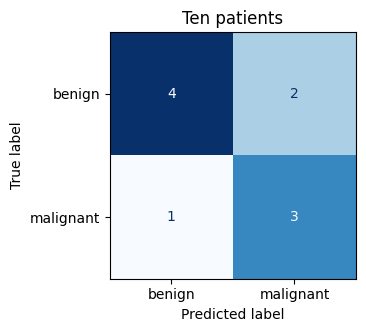

In [7]:
print(confusion_matrix(y_true, y_pred))
fig, ax = plt.subplots(figsize=(3.6, 3.2))
ConfusionMatrixDisplay.from_predictions(y_true, y_pred, display_labels=["benign", "malignant"],
                                        cmap="Blues", colorbar=False, ax=ax)
ax.set_title("Ten patients")
plt.show()

**What to look at.** Read it as true row, predicted column. Bottom row, the four
malignant tumours: 3 flagged, **1 missed** (true malignant, predicted benign: a *false
negative*). Top row, the six benign ones: 4 left alone, **2 flagged by mistake** (*false
positives*). Accuracy added the 3 and the 4 and stopped there, so it cannot tell a
missed tumour from a false alarm. `ConfusionMatrixDisplay.from_predictions` draws the
same table from labels; `from_estimator`, used in lesson 1, calls `predict` first.

**Try changing.** swap one false positive for a second false negative in `y_pred`:
accuracy does not move, the matrix does.

## 4. Precision and recall, counted and then printed

**Recall** is the share of the truly malignant that were flagged:
TP / (TP + FN), with true positives (TP) and false negatives (FN). **Precision** is the
share of the flagged that were truly malignant: TP / (TP + FP), with false positives
(FP). Same numerator, different denominator: recall divides by a row of the matrix,
precision by a column. `classification_report` prints both for each class.

*From:* lesson 1, slides *Precision and recall* and *Precision and recall, counted*.

### Your prediction, before you run the next cell

With the ten patients of atom 3 (TP = 3, FN = 1, FP = 2), what are recall
and precision for the malignant class?

In [8]:
tp = ((y_pred == 1) & (y_true == 1)).sum()
fn = ((y_pred == 0) & (y_true == 1)).sum()
fp = ((y_pred == 1) & (y_true == 0)).sum()
print(f"by hand: recall = {tp}/({tp}+{fn}) = {tp / (tp + fn):.2f}   precision = {tp}/({tp}+{fp}) = {tp / (tp + fp):.2f}")
print()
print(classification_report(y_true, y_pred, target_names=["benign", "malignant"]))

by hand: recall = 3/(3+1) = 0.75   precision = 3/(3+2) = 0.60

              precision    recall  f1-score   support

      benign       0.80      0.67      0.73         6
   malignant       0.60      0.75      0.67         4

    accuracy                           0.70        10
   macro avg       0.70      0.71      0.70        10
weighted avg       0.72      0.70      0.70        10



**What to look at.** Recall **0.75** (three of the four malignant tumours caught),
precision **0.60** (three of the five alerts were right): the report's `malignant` row
says the same. The report also has a row for benign, where the roles swap, and a
`support` column, which is the number of true cases of each class. The `accuracy`
line is the 0.7 of atom 3.

**Try changing.** flag every patient, `y_pred = np.ones(10, dtype=int)`: recall
becomes perfect, and precision shows what it cost.